### this script calculate the topic similarity between international and non-international collaborated papers

In [1]:
import pandas as pd
import numpy as np
import itertools
from multiprocessing import Pool
from tqdm import tqdm
from scipy.spatial import distance
import random
import seaborn as sns
import matplotlib.pyplot as plt

In [2]:
embedding_path = "/gpfs/slate-sciencegenome/Embeddings/Data/wos_embedding_specter_all.npz"

In [3]:
embedding_file = np.load(embedding_path)
embedding = embedding_file['emb']
uids = embedding_file['uids']

In [8]:
pub_all_path = "../../data/dropbox/LaborDivision/data/deriveddata/all/pub_author.csv"
pub_all = pd.read_csv(pub_all_path)
pub_all = pub_all.drop(columns=['seqno','lastname','num_author'])

In [5]:
uid_path = "../../data/dropbox/LaborDivision/data/cleanedraw/ostbk_uid.pkl"
uid_df = pd.read_pickle(uid_path)

In [6]:
pub_all['ost_bk'] = pub_all['ost_bk'].astype('str')
pub_all['uid'] = pub_all['ost_bk'].map(uid_df)

In [7]:
pub_all = pub_all[['uid','year','dis','cntry','alpha','intl','title']].drop_duplicates(subset=['uid','cntry'])

In [76]:
len(newidmap)

17072488

### reindex the paper with integer newid

In [8]:
newidmap = dict(zip(pub_all.uid.unique(), np.arange(len(pub_all.uid.unique()))))

In [10]:
pub_all['newid'] = pub_all['uid'].map(newidmap)

In [11]:
pub_all.head()

,uid,year,dis,cntry,alpha,intl,title,newid
0,WOS:000259648000022,2008,56,CAN,noalp,0,Cyclical and dose-dependent responses of adult...,0
3,WOS:000260516300012,2008,51,JPN,noalp,1,Biphasic effects of orexin-A on autonomic nerv...,1
5,WOS:000260516300012,2008,51,CHN,noalp,1,Biphasic effects of orexin-A on autonomic nerv...,1
8,WOS:000261972700004,2008,27,RUS,alpha,0,Decomposition of ozone in water at pH 4-8,2
10,WOS:000266456400005,2008,28,RUS,noalp,0,Chemical and morphological modification of com...,3


### select out papers and corrosponding embedding that are included in our analysis from the whole wos embedding

In [12]:
pub_uid = pub_all.uid.unique().tolist()
pub_uid_set = set(pub_uid)

In [13]:
filtered_id = []
filtered_vectors = []
for index, id in tqdm(enumerate(uids)):
    if id in pub_uid_set:
        newid = newidmap[id]
        filtered_id.append(newid)
        filtered_vectors.append(embedding[index])
filtered_vectors = np.array(filtered_vectors)
filtered_id = np.array(filtered_id)

84162157it [01:35, 884504.53it/s] 


check whether new structured arrays contains the right vectors


In [12]:
samples = random.sample(pub_uid,10)
samples

['WOS:000522232600006',
 'WOS:000252375000007',
 'WOS:000286515000034',
 'WOS:000354505100049',
 'WOS:000488303400038',
 'WOS:000312476000004',
 'WOS:000441492000056',
 'WOS:000278629100033',
 'WOS:000334688400027',
 'WOS:000457879100001']

In [29]:
index_raw = np.where(np.isin(uids,samples[5]))
embedding[index_raw[0]]

array([[ 0.9973679 ,  0.99661666, -0.6743574 , -0.99471176,  0.99838305,
         0.9987112 ,  0.9971731 , -0.99750656,  0.98573834, -0.96674573,
        -0.983236  ,  0.9501558 ,  0.99087465,  0.99778587,  0.99349445,
        -0.99884427,  0.97326773,  0.9895082 ,  0.99534005, -0.9983344 ,
         0.6729088 ,  0.9984282 , -0.9993006 , -0.9606443 ,  0.99786377,
        -0.99244654,  0.9980614 ,  0.9990411 ,  0.09753772,  0.9706568 ,
         0.99620837,  0.99718463, -0.98152494, -0.9993885 ,  0.9756127 ,
        -0.39958897,  0.8776507 , -0.9526649 , -0.9950888 , -0.9826828 ,
         0.3205416 , -0.78550357,  0.69172895,  0.98066473, -0.98997337,
         0.97271526,  0.99283546,  0.99915224,  0.09179509,  0.88976806,
        -0.941632  , -0.9993866 , -0.9986591 , -0.993594  ,  0.99504304,
        -0.9988826 ,  0.9979872 , -0.9989848 , -0.9953272 , -0.99806654,
         0.9995432 , -0.93020844, -0.9793206 , -0.99659586]],
      dtype=float32)

In [28]:

index_new = np.where(np.isin(filtered_id,newidmap[samples[5]]))
filtered_vectors[index_new[0]]

array([[ 0.9973679 ,  0.99661666, -0.6743574 , -0.99471176,  0.99838305,
         0.9987112 ,  0.9971731 , -0.99750656,  0.98573834, -0.96674573,
        -0.983236  ,  0.9501558 ,  0.99087465,  0.99778587,  0.99349445,
        -0.99884427,  0.97326773,  0.9895082 ,  0.99534005, -0.9983344 ,
         0.6729088 ,  0.9984282 , -0.9993006 , -0.9606443 ,  0.99786377,
        -0.99244654,  0.9980614 ,  0.9990411 ,  0.09753772,  0.9706568 ,
         0.99620837,  0.99718463, -0.98152494, -0.9993885 ,  0.9756127 ,
        -0.39958897,  0.8776507 , -0.9526649 , -0.9950888 , -0.9826828 ,
         0.3205416 , -0.78550357,  0.69172895,  0.98066473, -0.98997337,
         0.97271526,  0.99283546,  0.99915224,  0.09179509,  0.88976806,
        -0.941632  , -0.9993866 , -0.9986591 , -0.993594  ,  0.99504304,
        -0.9988826 ,  0.9979872 , -0.9989848 , -0.9953272 , -0.99806654,
         0.9995432 , -0.93020844, -0.9793206 , -0.99659586]],
      dtype=float32)

#### calculate each country-discipline pair

In [52]:
pub_all_dict = pub_all.groupby(['cntry','dis','intl'])['newid'].apply(list).to_dict()

In [62]:
cntrys = pub_all.cntry.unique()
dis = pub_all.dis.unique()
res = []
for c,d in tqdm(itertools.product(cntrys,dis)):
    try:
        uid_dome = pub_all_dict[(c,d,0)]
        uid_intl = pub_all_dict[(c,d,1)]
        
        index_dome = np.where(np.isin(filtered_id, uid_dome))[0]
        index_intl = np.where(np.isin(filtered_id, uid_intl))[0]
        
        embed_dome = filtered_vectors[index_dome]
        embed_intl = filtered_vectors[index_intl]

        embed_dome = np.mean(np.array(embed_dome),axis=0)
        embed_intl = np.mean(np.array(embed_intl),axis=0)

        similarity = 1-distance.cosine(embed_dome, embed_intl)
        res.append([c,d,similarity])
    except KeyError:
        pass

3574it [32:57,  1.62it/s]/home/miaoli/conda/envs/myenv/lib/python3.8/site-packages/numpy/core/fromnumeric.py:3464: RuntimeWarning: Mean of empty slice.
  return _methods._mean(a, axis=axis, dtype=dtype,
/home/miaoli/conda/envs/myenv/lib/python3.8/site-packages/numpy/core/_methods.py:184: RuntimeWarning: invalid value encountered in divide
  ret = um.true_divide(
28743it [2:30:30,  3.18it/s] 


In [64]:
pd.DataFrame(res).to_csv("cntry_similarity_dis.csv",index=False)

In [5]:
res_df = pd.read_csv("cntry_similarity_dis.csv",names=['cntry','dis','similarity'])

In [6]:
stgroup_path = '../../data/dropbox/LaborDivision/data/additionaldata/cntry_classification/cntry_group_meta.csv'
stgroup_df=pd.read_csv(stgroup_path)[['Code','ST']].drop_duplicates()
stgroup_df=stgroup_df.replace(to_replace={'ST':{'Others':'Lagging'}})
stgroup_df.head()

,Code,ST
0,AFG,Lagging
1,ALB,Lagging
2,DZA,Lagging
3,AND,Lagging
4,AGO,Lagging


In [7]:
res_df = res_df.merge(stgroup_df, left_on='cntry', right_on='Code')

In [9]:
res_df = res_df.groupby(['cntry','ST'])['similarity'].mean().reset_index()

/tmp/ipykernel_542159/621477607.py:4: FutureWarning: Passing `palette` without assigning `hue` is deprecated.
  sns.stripplot(x='ST',y='similarity',data=res_df,ax=ax, order=order, palette=color)


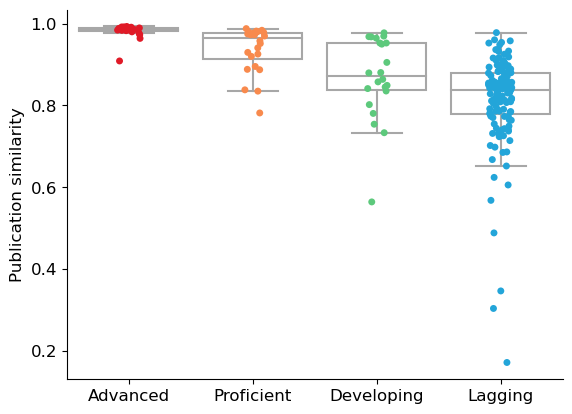

In [10]:
fig, ax=plt.subplots()
color={'Advanced':'#E01A27','Proficient':'#F88A4D','Developing':'#5DC97C','Lagging':'#23A5D9'}
order = ['Advanced','Proficient','Developing','Lagging']
sns.stripplot(x='ST',y='similarity',data=res_df,ax=ax, order=order, palette=color)
sns.boxplot(x='ST',y='similarity',data=res_df,
            boxprops={'facecolor':'none', 'edgecolor':'#A7A7A7'},
            medianprops={'color':'#A7A7A7'},
            whiskerprops={'color':'#A7A7A7'},
            capprops={'color':'#A7A7A7'},
            order=order,
            fliersize=0,
            ax=ax)
ax.set_ylabel("Publication similarity", fontsize=12)
ax.set_xlabel("")
ax.tick_params(axis='both', which='major', labelsize=12)
ax.spines['top'].set_visible(False)
ax.spines['right'].set_visible(False)

In [12]:
res_df[res_df.ST=='Lagging']

,cntry,ST,similarity
0,AFG,Lagging,0.830219
1,AGO,Lagging,0.843201
2,ALB,Lagging,0.814250
3,AND,Lagging,0.791784
4,ARE,Lagging,0.948181
...,...,...,...
190,WSM,Lagging,0.806810
191,XKX,Lagging,0.789586
192,YEM,Lagging,0.805550
194,ZMB,Lagging,0.850515
